In [ ]:
# Install CloudDrift
!pip install -q "zarr<3" "xarray==2025.1.2" clouddrift

# Install Cartopy
!pip install -q cartopy

In [ ]:
# Import required libraries
import clouddrift as cd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from clouddrift.datasets import gdp6h
from clouddrift.ragged import subset
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
from matplotlib.patches import Circle
from sklearn.model_selection import train_test_split


# Load the 6 hourly Global Drifter Program dataset
ds = gdp6h()
ds

<xarray.Dataset> Size: 2GB
Dimensions:                (traj: 28706, obs: 48840300)
Coordinates:
    id                     (traj) int64 230kB ...
    time                   (obs) datetime64[ns] 391MB ...
Dimensions without coordinates: traj, obs
Data variables: (12/48)
    BuoyTypeManufacturer   (traj) <U20 2MB ...
    BuoyTypeSensorArray    (traj) <U20 2MB ...
    CurrentProgram         (traj) float64 230kB ...
    DeployingCountry       (traj) <U20 2MB ...
    DeployingShip          (traj) <U20 2MB ...
    DeploymentComments     (traj) <U20 2MB ...
    ...                     ...
    start_lon              (traj) float32 115kB ...
    temp                   (obs) float32 195MB ...
    typebuoy               (traj) |S10 287kB ...
    typedeath              (traj) int8 29kB ...
    ve                     (obs) float32 195MB ...
    vn                     (obs) float32 195MB ...
Attributes: (12/18)
    Conventions:          CF-1.6
    acknowledgement:      Lumpkin, Rick; Centurioni, Luca (2019). NOAA Global...
    contributor_name:     NOAA Global Drifter Program
    contributor_role:     Data Acquisition Center
    date_created:         2025-07-14T15:15:03.441003
    doi:                  10.25921/7ntx-z961
    ...                   ...
    publisher_name:       GDP Drifter DAC
    publisher_url:        https://www.aoml.noaa.gov/phod/gdp
    summary:              Global Drifter Program six-hourly data
    time_coverage_end:    2025-01-20:00:00:00Z
    time_coverage_start:  1979-02-15:00:00:00Z
    title:                Global Drifter Program drifting buoy collection

In [ ]:
# LAT and LON of full North Atlantic Ocean Basin
LAT_MIN, LAT_MAX = 10.0, 45.0
LON_MIN, LON_MAX = -80.0, -20.0
region_name = "North Atlantic Ocean Basin"

In [ ]:
#--------------------------------------------------------
#  DATA WRANGLING
#--------------------------------------------------------

# ------------------------------------------------------------------
# 1. Get observations within our region
# ------------------------------------------------------------------
lat = ds['lat'].values
lon = ((ds['lon'].values + 180) % 360) - 180

in_box = ((lat >= LAT_MIN) & (lat < LAT_MAX) &
          (lon >= LON_MIN) & (lon < LON_MAX))

# ------------------------------------------------------------------
# 2. Give every observation its drifter id (id and rowsize are per trajectory)
# ------------------------------------------------------------------
obs_id = np.repeat(ds['id'].values, ds['rowsize'].values)
assert len(obs_id) == ds.sizes['obs'], "rowsize does not add up to the number of observations"

# ------------------------------------------------------------------
# 3. Build the dataframe
# ------------------------------------------------------------------
df = pd.DataFrame({
    'id':            obs_id[in_box],
    'time':          ds['time'].values[in_box],
    'lat':           lat[in_box],
    'lon':           lon[in_box],
    've':            ds['ve'].values[in_box],
    'vn':            ds['vn'].values[in_box],
    'temp':          ds['temp'].values[in_box],
    'drogue_status': ds['drogue_status'].values[in_box],
})

df = df.sort_values(['id', 'time'], kind='stable').reset_index(drop=True)

# ------------------------------------------------------------------
# 4. Quick look
# ------------------------------------------------------------------
print(f"{len(df):,} observations from {df['id'].nunique():,} drifters")
print(f"{df['time'].min():%Y-%m-%d} to {df['time'].max():%Y-%m-%d}")


6,116,067 observations from 3,896 drifters
1989-10-31 to 2025-01-20


In [ ]:
# ------------------------------------------------------------------
# Split df into custom quarters (all years pooled)
# ------------------------------------------------------------------
QUARTER_OF_MONTH = {3: 1, 4: 1, 5: 1,         # Q1: Mar - May
                    6: 2, 7: 2, 8: 2,         # Q2: Jun - Aug
                    9: 3, 10: 3, 11: 3,        # Q3: Sep - Nov
                    12: 4, 1: 4, 2: 4}       # Q4: Dec - Feb

quarter = df['time'].dt.month.map(QUARTER_OF_MONTH) # assign each month to a quarter

df_q1 = df[quarter == 1].copy()          # March - May
df_q2 = df[quarter == 2].copy()          # June - August
df_q3 = df[quarter == 3].copy()          # September - November
df_q4 = df[quarter == 4].copy()          # December - February

# ------------------------------------------------------------------
# Summary
# ------------------------------------------------------------------
for name, q in [('df_q1 (Mar-May)', df_q1), ('df_q2 (Jun-Aug)', df_q2),
                ('df_q3 (Sep-Nov)', df_q3), ('df_q4 (Dec-Feb)', df_q4)]:
    print(f"{name}: {len(q):,} observations from {q['id'].nunique():,} drifters")

assert len(df_q1) + len(df_q2) + len(df_q3) + len(df_q4) == len(df), \
    "some rows were not assigned to a quarter (check for missing time values)"

df_q1 (Mar-May): 1,474,332 observations from 3,006 drifters
df_q2 (Jun-Aug): 1,577,383 observations from 3,089 drifters
df_q3 (Sep-Nov): 1,597,160 observations from 3,109 drifters
df_q4 (Dec-Feb): 1,467,192 observations from 3,010 drifters


## Model 2 (seasonal Markov chains) - Built to match Model 1's evaluation

- **Four separate seasonal transition matrices:** The dataset `df` is split into four quarters (`df_q1` for Mar–May, `df_q2` for Jun–Aug, `df_q3` for Sep–Nov, and `df_q4` for Dec–Feb), and a separate $210,000 \times 210,000$ sparse transition matrix $P_q$ is constructed for each season $q$.
- **5-fold cross-validation split by drifter:** A single 5-fold split on unique drifter IDs is shared across all four seasons, ensuring a drifter is never in the training set for one season and the test set for another.
- **Strict seasonal and fold isolation:** Within each fold, $P_q$ is estimated solely from consecutive 6-hourly fixes of that fold's training drifters occurring inside season $q$.
- **Same evaluation metrics as Model 1:** Great-circle (haversine) MAE in km of the most-likely cell (`top1`) vs. a persistence baseline and skill vs. persistence at 3, 10, and 15 days (all 5 folds) and 14 and 30 days (Fold 4), plus the Energy Score using 500 Monte Carlo particles at 3, 10, and 15 days (Fold 4).
- **Intra-season window filtering and coverage:** Candidate test windows are constructed per season so that the **entire forecast window lies within a single season** (excluding cross-season transitions). A window is then scored only if its start cell was visited in that season's training data, with `Coverage_%` reporting the percentage of intra-season test windows that meet this condition.

In [ ]:
#-----------------------------------------------------------
# DATA SUMMARY FOR OUR REGION
#-----------------------------------------------------------
datasets = {'Quarter 1' : df_q1, 'Quarter 2' : df_q2 , 'Quarter 3' : df_q3 , 'Quarter 4' : df_q4}

for name, q in datasets.items():
  print(' ' * 20, name)
  total_rows = len(q)
  print(f"--- DATA SUMMARY (Total Observations: {total_rows:,}) ---\n")

  # Aggregates missing counts, valid counts, percentages, and data types
  missing_summary = pd.DataFrame({
      'Missing Count': q.isna().sum(),
      'Valid Count': q.notna().sum(),
      'Missing (%)': (q.isna().mean() * 100).round(2),
      'Data Type': q.dtypes
  }).sort_values(by='Missing Count', ascending=False)

  print(missing_summary)
  print("-" * 70)

  # Identifies rows with no missing values versus rows containing at least one NaN
  complete_rows = q.dropna().shape[0]
  incomplete_rows = total_rows - complete_rows

  print(f"Complete Rows:      {complete_rows:,} ({complete_rows / total_rows:.2%})")
  print(f"Incomplete Rows:    {incomplete_rows:,} ({incomplete_rows / total_rows:.2%})")
  print("-" * 70)
  print('\n')

                     Quarter 1
--- DATA SUMMARY (Total Observations: 1,474,332) ---

               Missing Count  Valid Count  Missing (%)       Data Type
temp                   94251      1380081         6.39         float32
ve                      1688      1472644         0.11         float32
vn                      1688      1472644         0.11         float32
id                         0      1474332         0.00           int64
lon                        0      1474332         0.00         float64
lat                        0      1474332         0.00         float64
time                       0      1474332         0.00  datetime64[ns]
drogue_status              0      1474332         0.00            bool
----------------------------------------------------------------------
Complete Rows:      1,378,668 (93.51%)
Incomplete Rows:    95,664 (6.49%)
----------------------------------------------------------------------


                     Quarter 2
--- DATA SUMMARY (Total Obs

In [ ]:
# ==================================================================
# SHARED SETUP: grid, helper functions and metrics (same as Model 1)
# ==================================================================
from sklearn.model_selection import KFold
from scipy.sparse import coo_matrix, csr_matrix

SEED = 42
K = 5
RES = 0.1

N_LAT = int(round((LAT_MAX - LAT_MIN) / RES))   # 350
N_LON = int(round((LON_MAX - LON_MIN) / RES))   # 600
N_CELLS = N_LAT * N_LON
N_STATES = N_CELLS                              # 210,000

quarter_names = {1: 'Mar-May', 2: 'Jun-Aug', 3: 'Sep-Nov', 4: 'Dec-Feb'}
quarter_frames = {1: df_q1, 2: df_q2, 3: df_q3, 4: df_q4}


def to_state(lat, lon):
    """(lat, lon) -> 1D state index. Origin (state 0) = north-west corner; rows go south, columns go east."""
    lat_idx = np.floor((LAT_MAX - np.asarray(lat)) / RES).astype(np.int64)
    lon_idx = np.floor((np.asarray(lon) - LON_MIN) / RES).astype(np.int64)
    lat_idx = np.clip(lat_idx, 0, N_LAT - 1)
    lon_idx = np.clip(lon_idx, 0, N_LON - 1)
    return lat_idx * N_LON + lon_idx


def state_to_latlon(state):
    """State index -> (lat, lon) of the cell centre."""
    state = np.asarray(state)
    lat = LAT_MAX - (state // N_LON + 0.5) * RES
    lon = LON_MIN + (state % N_LON + 0.5) * RES
    return lat, lon


def count_transitions(train_df):
    """Sparse matrix of transition counts between consecutive fixes of the same drifter exactly 6 h apart."""
    d = train_df[['id', 'time', 'lat', 'lon']].dropna()
    d = d.sort_values(['id', 'time'], kind='stable')

    state = to_state(d['lat'].values, d['lon'].values)
    ids = d['id'].values
    times = d['time'].values

    valid = (ids[1:] == ids[:-1]) & ((times[1:] - times[:-1]) == np.timedelta64(6, 'h'))
    src = state[:-1][valid]
    dst = state[1:][valid]

    return coo_matrix((np.ones(len(src)), (src, dst)), shape=(N_STATES, N_STATES)).tocsr()


def row_normalise(counts):
    """Counts -> transition probability matrix P. Rows of unvisited cells stay all-zero."""
    row_sums = np.asarray(counts.sum(axis=1)).ravel()
    inv = np.zeros_like(row_sums)
    nz = row_sums > 0
    inv[nz] = 1.0 / row_sums[nz]
    P = csr_matrix(counts.multiply(inv[:, None]))
    return P, nz


def hav(lat1, lon1, lat2, lon2):
    """Great-circle (haversine) distance in km."""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return R * 2 * np.arcsin(np.sqrt(a))


def build_pairs_xy(test_df, n_steps=12):
    """Pairs of fixes from the same drifter exactly n_steps * 6 h apart (start cell, end position)."""
    d = test_df[['id', 'time', 'lat', 'lon']].dropna()
    d = d.sort_values(['id', 'time'], kind='stable')

    ids, times = d['id'].values, d['time'].values
    lat, lon = d['lat'].values, d['lon'].values
    state = to_state(lat, lon)

    ok = ((ids[n_steps:] == ids[:-n_steps]) &
          ((times[n_steps:] - times[:-n_steps]) == np.timedelta64(6 * n_steps, 'h')))

    return pd.DataFrame({
        'id': ids[:-n_steps][ok],
        'start': state[:-n_steps][ok],
        'end': state[n_steps:][ok],
        'lat0': lat[:-n_steps][ok], 'lon0': lon[:-n_steps][ok],
        'lat1': lat[n_steps:][ok], 'lon1': lon[n_steps:][ok]
    })


def forecast_points(P_mat, start_states, n_steps, chunk_size=500, prune=1e-6):
    """Propagate each start cell n_steps through P. Returns (top1, mean): the most-likely cell centre
    and the probability-weighted mean position of the n-step distribution."""
    all_lat, all_lon = state_to_latlon(np.arange(N_STATES))
    P_csr = P_mat.tocsr()
    n = len(start_states)
    top1 = np.empty((n, 2))
    mean = np.empty((n, 2))

    for a in range(0, n, chunk_size):
        b = min(a + chunk_size, n)
        V = csr_matrix((np.ones(b - a), (np.arange(b - a), start_states[a:b])), shape=(b - a, N_STATES))

        for _ in range(n_steps):
            V = V @ P_csr
            if prune:
                V.data[V.data < prune] = 0
                V.eliminate_zeros()

        mass = np.asarray(V.sum(axis=1)).ravel()
        best = np.asarray(V.argmax(axis=1)).ravel()
        ok = mass > 0
        s_lat, s_lon = state_to_latlon(start_states[a:b])

        top1[a:b, 0] = np.where(ok, all_lat[best], s_lat)
        top1[a:b, 1] = np.where(ok, all_lon[best], s_lon)

        with np.errstate(invalid='ignore', divide='ignore'):
            mean[a:b, 0] = np.where(ok, (V @ all_lat) / mass, s_lat)
            mean[a:b, 1] = np.where(ok, (V @ all_lon) / mass, s_lon)

    return top1, mean


# ------------------------------------------------------------------
# Simulates many drifters moving cell to cell, picking each next cell at random using the probabilities in P.
# It moves all the drifters at once, which is much faster than doing them one by one.
# ------------------------------------------------------------------
def make_sampler(P_mat):
    P = P_mat.tocsr()
    P.sort_indices()
    indptr, indices, data = P.indptr, P.indices, P.data
    n_rows = P.shape[0]
    row_of = np.repeat(np.arange(n_rows), np.diff(indptr))

    cum = np.cumsum(data)
    start_cum = np.concatenate(([0.0], cum))[indptr[:-1]]
    within = cum - start_cum[row_of]                      # cumulative probability within each row
    nonempty = np.diff(indptr) > 0
    within[indptr[1:][nonempty] - 1] = 1.0                # remove float drift: each row ends at exactly 1
    key = row_of + within                                 # row r occupies (r, r + 1], increasing overall
    return indptr, indices, key


def sample_end_states(sampler, start_states, n_steps, n_sims, rng):
    """Simulate n_sims particles per start cell for n_steps. Returns array (n_starts, n_sims) of end states."""
    indptr, indices, key = sampler
    start_states = np.asarray(start_states, dtype=np.int64)
    cur = np.repeat(start_states, n_sims)
    for _ in range(n_steps):
        alive = indptr[cur + 1] > indptr[cur]             # cells never left in training stay put
        u = rng.random(cur.size)
        pos = np.searchsorted(key, cur + u, side='right')
        pos = np.clip(pos, 0, len(indices) - 1)
        cur = np.where(alive, indices[pos], cur)
    return cur.reshape(len(start_states), n_sims)


In [ ]:
# ==================================================================
# 5-FOLD CROSS-VALIDATION: ONE SEASONAL MARKOV MATRIX PER FOLD AND SEASON
# ==================================================================
all_ids = df['id'].unique()
kf = KFold(n_splits=K, shuffle=True, random_state=SEED)

cv_results = []
for fold, (train_idx, test_idx) in enumerate(kf.split(all_ids), start=1):
    train_ids = all_ids[train_idx]
    test_ids = all_ids[test_idx]
    assert set(train_ids).isdisjoint(test_ids)            # no drifter is in both sets

    print(f"\n=== FOLD {fold} of {K}: {len(train_ids):,} train drifters / {len(test_ids):,} test drifters ===")

    seasons = {}
    for q, frame in quarter_frames.items():
        df_train = frame[frame['id'].isin(train_ids)]
        df_test = frame[frame['id'].isin(test_ids)]       # held-out drifters only
        assert df_train['id'].isin(test_ids).sum() == 0
        assert df_test['id'].isin(train_ids).sum() == 0

        counts = count_transitions(df_train)
        P, visited = row_normalise(counts)

        rs = np.asarray(P.sum(axis=1)).ravel()
        assert np.allclose(rs[visited], 1.0), f"Fold {fold} Q{q}: visited rows must sum to 1"
        assert np.all(rs[~visited] == 0), f"Fold {fold} Q{q}: unvisited rows should be empty"

        print(f"  Q{q} ({quarter_names[q]}): {int(counts.sum()):>9,} transitions | "
              f"cells visited {visited.sum():>7,}/{N_STATES:,} ({visited.mean():.1%}) | "
              f"non-zero entries {P.nnz:>9,} | test fixes {len(df_test):>8,}")

        seasons[q] = {'P': P, 'visited': visited, 'df_test': df_test, 'n_transitions': int(counts.sum())}

    cv_results.append({'fold': fold, 'train_ids': train_ids, 'test_ids': test_ids, 'seasons': seasons})



=== FOLD 1 of 5: 3,116 train drifters / 780 test drifters ===
  Q1 (Mar-May): 1,193,307 transitions | cells visited 167,169/210,000 (79.6%) | non-zero entries   578,982 | test fixes  276,329
  Q2 (Jun-Aug): 1,277,115 transitions | cells visited 165,996/210,000 (79.0%) | non-zero entries   590,884 | test fixes  295,362
  Q3 (Sep-Nov): 1,300,394 transitions | cells visited 163,706/210,000 (78.0%) | non-zero entries   599,049 | test fixes  291,843
  Q4 (Dec-Feb): 1,192,786 transitions | cells visited 164,758/210,000 (78.5%) | non-zero entries   569,540 | test fixes  269,693

=== FOLD 2 of 5: 3,117 train drifters / 779 test drifters ===
  Q1 (Mar-May): 1,155,118 transitions | cells visited 166,970/210,000 (79.5%) | non-zero entries   572,192 | test fixes  314,572
  Q2 (Jun-Aug): 1,245,886 transitions | cells visited 166,877/210,000 (79.5%) | non-zero entries   589,288 | test fixes  326,664
  Q3 (Sep-Nov): 1,255,359 transitions | cells visited 163,921/210,000 (78.1%) | non-zero entries   5

## Forecast evaluation: MAE and skill vs persistence

- **Seasonal partitioning & intra-season windows:** Observations across all years are pooled by meteorological season (`Q1`: Mar–May, `Q2`: Jun–Aug, `Q3`: Sep–Nov, `Q4`: Dec–Feb) before splitting by drifter ID. Test windows (start fix → fix *n* steps later, same drifter, spaced exactly $6n$ hours apart) are constructed independently within each season's held-out subset, ensuring that every evaluated trajectory remains entirely within a single season and cross-season boundaries are excluded.
- **Start-cell filtering (`Coverage_%`):** Only intra-season test windows whose start cell was visited by training drifters in that same season ($P_q$ row sum $> 0$) are scored; `Coverage_%` reports the share of intra-season held-out windows meeting this criterion.
- **Markov forecast:** Centre of the most likely cell of the *n*-step distribution (`top1`), propagated through that season's transition matrix $P_q$.
- **Persistence baseline:** Assumes the drifter remains stationary at its initial `(lat0, lon0)` position.
- **Error & skill:** Error is the great-circle (haversine) distance in km to the true end position, with **Skill = 1 − (MAE_Markov / MAE_persistence)**.
- **Pooling across seasons:** Within each fold, seasonal metrics are pooled using a pair-weighted average (`Eval_Pairs`) so the headline numbers are directly comparable with Model 1.

In [ ]:
# ==================================================================
# MULTI-HORIZON EVALUATION (seasonal Markov chains vs persistence)
# ==================================================================
def evaluate_seasonal_cv(cv_results, horizons=(12, 40, 60), folds=None):
    """One row per (fold, season, horizon). horizons are in 6-hour steps (12 = 3 days, 40 = 10 days)."""
    rows = []
    for rec in cv_results:
        if folds is not None and rec['fold'] not in folds:
            continue
        for q, s in rec['seasons'].items():
            for n_steps in horizons:
                pr = build_pairs_xy(s['df_test'], n_steps=n_steps)
                n_total = len(pr)
                if n_total == 0:
                    continue
                pr = pr[s['visited'][pr['start'].values]].reset_index(drop=True)   # start cell seen in training
                if len(pr) == 0:
                    continue

                start = pr['start'].values
                lat0, lon0 = pr['lat0'].values, pr['lon0'].values
                lat1, lon1 = pr['lat1'].values, pr['lon1'].values

                uniq, inv_ = np.unique(start, return_inverse=True)
                top1, _ = forecast_points(s['P'], uniq, n_steps, chunk_size=500, prune=1e-6)

                d_model = hav(lat1, lon1, top1[inv_, 0], top1[inv_, 1])
                d_persist = hav(lat1, lon1, lat0, lon0)
                mae_m, mae_p = d_model.mean(), d_persist.mean()

                rows.append({
                    'Fold': rec['fold'], 'Quarter': q, 'Season': quarter_names[q],
                    'Horizon_Days': n_steps * 6 / 24,
                    'Eval_Pairs': len(pr), 'Coverage_%': 100 * len(pr) / n_total,
                    'Markov_MAE_km': mae_m, 'Persistence_MAE_km': mae_p,
                    'Skill_vs_Persistence_%': 100 * (1 - mae_m / mae_p),
                })
    return pd.DataFrame(rows)


def pool_over_seasons(res):
    """Pair-weighted pooling of the four seasons inside each (fold, horizon)."""
    out = []
    for (fold, hz), g in res.groupby(['Fold', 'Horizon_Days']):
        w = g['Eval_Pairs'].values
        mae_m = np.average(g['Markov_MAE_km'], weights=w)
        mae_p = np.average(g['Persistence_MAE_km'], weights=w)
        out.append({'Fold': fold, 'Horizon_Days': hz, 'Eval_Pairs': int(w.sum()),
                    'Coverage_%': np.average(g['Coverage_%'], weights=w),
                    'Markov_MAE_km': mae_m, 'Persistence_MAE_km': mae_p,
                    'Skill_vs_Persistence_%': 100 * (1 - mae_m / mae_p)})
    return pd.DataFrame(out)


cv_eval_seasonal = evaluate_seasonal_cv(cv_results, horizons=(12, 40, 60))
cv_eval_pooled = pool_over_seasons(cv_eval_seasonal)

print("=" * 70)
print("PER FOLD (seasons pooled)")
print("=" * 70)
display(cv_eval_pooled)

print("\n" + "=" * 70)
print("AGGREGATED ACROSS ALL 5 FOLDS (seasons pooled)  <- compare with Model 1")
print("=" * 70)
display(cv_eval_pooled.groupby('Horizon_Days')[['Markov_MAE_km', 'Persistence_MAE_km',
                                               'Skill_vs_Persistence_%', 'Coverage_%']].mean().reset_index())

print("\n" + "=" * 70)
print("PER SEASON (mean over 5 folds)")
print("=" * 70)
display(cv_eval_seasonal.groupby(['Quarter', 'Season', 'Horizon_Days'])[
    ['Eval_Pairs', 'Coverage_%', 'Markov_MAE_km', 'Persistence_MAE_km', 'Skill_vs_Persistence_%']].mean().reset_index())


PER FOLD (seasons pooled)


,Fold,Horizon_Days,Eval_Pairs,Coverage_%,Markov_MAE_km,Persistence_MAE_km,Skill_vs_Persistence_%
0,1,3.0,997968,92.318936,53.600371,52.453561,-2.186333
1,1,10.0,895825,92.509236,130.294399,133.821659,2.635792
2,1,15.0,826478,92.599418,170.860601,177.469090,3.723741
3,2,3.0,1149673,93.082774,51.629671,49.993004,-3.273791
4,2,10.0,1034670,93.190959,126.191421,128.314105,1.654287
5,2,15.0,956367,93.241345,165.350141,170.567571,3.058864
6,3,3.0,1072535,92.691734,51.778179,50.254437,-3.032054
7,3,10.0,964543,92.852730,126.397333,129.043834,2.050855
8,3,15.0,890917,92.935665,166.221693,171.869508,3.286106
9,4,3.0,1107852,91.737331,52.275335,50.923807,-2.654022



AGGREGATED ACROSS ALL 5 FOLDS (seasons pooled)  <- compare with Model 1


,Horizon_Days,Markov_MAE_km,Persistence_MAE_km,Skill_vs_Persistence_%,Coverage_%
0,3.0,52.443548,51.063907,-2.708770,92.597216
1,10.0,127.961914,131.067234,2.363476,92.758369
2,15.0,168.059997,174.451409,3.658711,92.845198



PER SEASON (mean over 5 folds)


,Quarter,Season,Horizon_Days,Eval_Pairs,Coverage_%,Markov_MAE_km,Persistence_MAE_km,Skill_vs_Persistence_%
0,1,Mar-May,3.0,260402.8,92.546942,53.964376,51.882225,-4.012156
1,1,Mar-May,10.0,233696.8,92.710480,129.213734,129.657241,0.341299
2,1,Mar-May,15.0,215644.0,92.808239,167.918539,170.506709,1.519699
3,2,Jun-Aug,3.0,280688.6,93.076941,52.163274,51.528401,-1.239328
4,2,Jun-Aug,10.0,252739.4,93.201443,128.575493,134.470093,4.379926
5,2,Jun-Aug,15.0,233595.8,93.257607,169.557767,180.431560,6.024281
6,3,Sep-Nov,3.0,283545.0,92.828480,51.816922,50.407872,-2.814804
7,3,Sep-Nov,10.0,255652.2,93.017268,127.480012,129.859105,1.807467
8,3,Sep-Nov,15.0,236498.8,93.114238,168.069408,172.617478,2.607219
9,4,Dec-Feb,3.0,257212.2,91.869811,51.896060,50.449743,-2.872539


## Extended horizons (14 and 30 days) on Fold 4

Same as Model 1: the longer horizons are run on Fold 4 only. Fold 4 is fixed in Model 2 as it is the best performing fold in Model 2 as well.

Fold 4: seasons pooled


,Fold,Horizon_Days,Eval_Pairs,Coverage_%,Markov_MAE_km,Persistence_MAE_km,Skill_vs_Persistence_%
0,4,3.0,1107852,91.737331,52.275335,50.923807,-2.654022
1,4,10.0,996808,91.939854,127.375328,131.192747,2.909779
2,4,14.0,935948,92.043993,159.866227,166.772118,4.140915
3,4,15.0,921055,92.071305,167.299001,175.008127,4.405010
4,4,30.0,707883,92.310844,263.600053,279.883254,5.817854


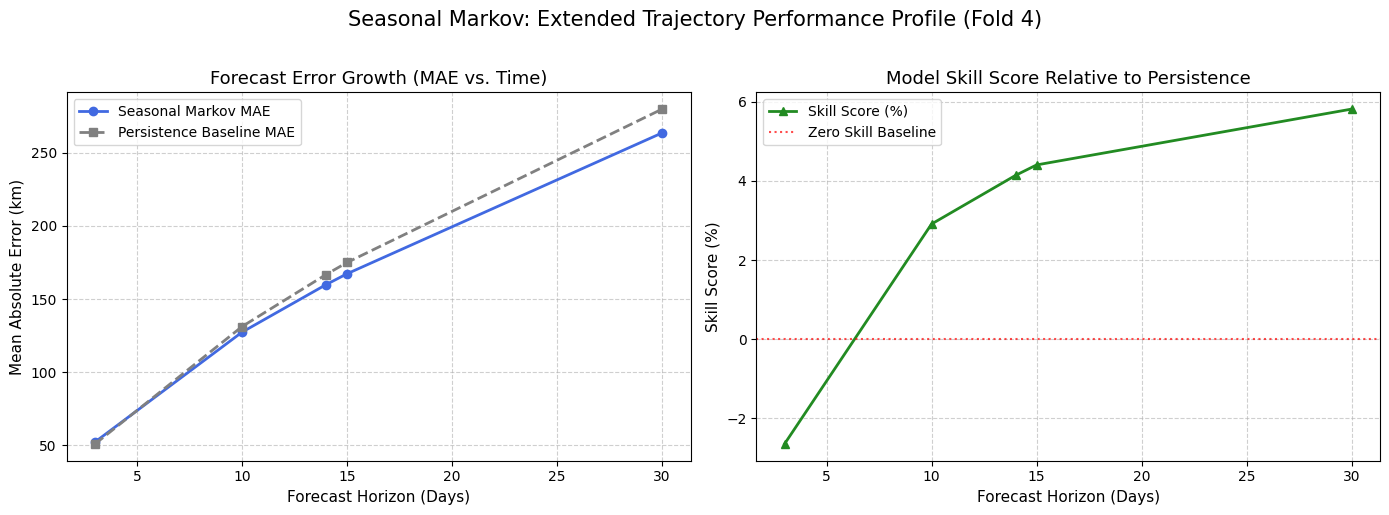

In [ ]:
# ==================================================================
# EXTENDED HORIZON EVALUATION ON FOLD 4 (14 and 30 days) AND PLOTS
# ==================================================================
FOLD_EXT = 4 # Fold number
target_days = [14, 30]
horizons_steps = [int(days * 24 / 6) for days in target_days]       # 56 and 120 steps

ext_seasonal = evaluate_seasonal_cv(cv_results, horizons=tuple(horizons_steps), folds=[FOLD_EXT])
base_seasonal = cv_eval_seasonal[cv_eval_seasonal['Fold'] == FOLD_EXT]

fold_ext_seasonal = pd.concat([base_seasonal, ext_seasonal]).reset_index(drop=True)
fold_ext = pool_over_seasons(fold_ext_seasonal).sort_values('Horizon_Days').reset_index(drop=True)

print(f"Fold {FOLD_EXT}: seasons pooled")
display(fold_ext)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fold_ext['Horizon_Days'], fold_ext['Markov_MAE_km'], marker='o', color='royalblue', linewidth=2, label='Seasonal Markov MAE')
axes[0].plot(fold_ext['Horizon_Days'], fold_ext['Persistence_MAE_km'], marker='s', color='gray', linestyle='--', linewidth=2, label='Persistence Baseline MAE')
axes[0].set_title('Forecast Error Growth (MAE vs. Time)', fontsize=13)
axes[0].set_xlabel('Forecast Horizon (Days)', fontsize=11)
axes[0].set_ylabel('Mean Absolute Error (km)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

axes[1].plot(fold_ext['Horizon_Days'], fold_ext['Skill_vs_Persistence_%'], marker='^', color='forestgreen', linewidth=2, label='Skill Score (%)')
axes[1].axhline(0, color='red', linestyle=':', alpha=0.7, label='Zero Skill Baseline')
axes[1].set_title('Model Skill Score Relative to Persistence', fontsize=13)
axes[1].set_xlabel('Forecast Horizon (Days)', fontsize=11)
axes[1].set_ylabel('Skill Score (%)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.suptitle(f"Seasonal Markov: Extended Trajectory Performance Profile (Fold {FOLD_EXT})", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()


## Probabilistic evaluation: Energy Score (Fold 4: 3, 10 and 15 days)

For each start cell, 500 Monte Carlo particles are run through that season's `P_q`. The cloud is scored against the real end positions of held-out drifters that started in that cell:

`ES = E‖X − y‖ − ½ E‖X − X′‖` (haversine distance, km; lower is better), and **Skill = 1 − (ES_Markov / ES_persistence)**.

Start cells are subsampled to at most 500 per season and horizon, and cells with fewer than 5 test windows are skipped. Seasons are pooled weighted by number of start cells scored.

In [ ]:
# ==================================================================
# STOCHASTIC ENERGY SCORE EVALUATION (Fold 4 - seasonal Markov VS Persistence)
# ==================================================================
def evaluate_fold_energy_score_seasonal(cv_results, fold_num=4, horizons=(12, 40, 60), n_sims=500):
    rng = np.random.default_rng(42)
    rec = next(r for r in cv_results if r['fold'] == fold_num)
    rows = []

    for q, s in rec['seasons'].items():
        sampler = make_sampler(s['P'])

        for n_steps in horizons:
            days = n_steps * 6 / 24

            pr = build_pairs_xy(s['df_test'], n_steps=n_steps)
            if len(pr) == 0:
                continue
            pr = pr[s['visited'][pr['start'].values]].reset_index(drop=True)
            if len(pr) == 0:
                continue

            unique_starts = pr['start'].unique()
            if len(unique_starts) > 500:
                unique_starts = rng.choice(unique_starts, 500, replace=False)

            ends = sample_end_states(sampler, unique_starts, n_steps, n_sims, rng)
            sim_dict = {c: e for c, e in zip(unique_starts, ends)}

            es_model, es_persist = [], []
            for start_cell in unique_starts:
                subset_df = pr.loc[pr['start'] == start_cell]
                if len(subset_df) < 5:
                    continue

                lat_r, lon_r = state_to_latlon(subset_df['end'].values)      # real end cells

                # --- Markov prediction cloud ---
                u, cnts = np.unique(sim_dict[start_cell], return_counts=True)
                w = cnts / cnts.sum()
                lat_u, lon_u = state_to_latlon(u)
                e_xy = (hav(lat_r[:, None], lon_r[:, None], lat_u[None, :], lon_u[None, :]) * w).sum(axis=1)
                e_xx = w @ hav(lat_u[:, None], lon_u[:, None], lat_u[None, :], lon_u[None, :]) @ w
                es_m = e_xy.mean() - 0.5 * e_xx

                # --- Persistence "cloud" = the starting positions of these windows ---
                lat0_arr, lon0_arr = subset_df['lat0'].values, subset_df['lon0'].values
                e_px = hav(lat_r[:, None], lon_r[:, None], lat0_arr[None, :], lon0_arr[None, :]).mean(axis=1)
                e_pp = hav(lat0_arr[:, None], lon0_arr[:, None], lat0_arr[None, :], lon0_arr[None, :]).mean()
                es_p = e_px.mean() - 0.5 * e_pp

                es_model.append(es_m)
                es_persist.append(es_p)

            if len(es_model) > 0:
                mean_m, mean_p = np.mean(es_model), np.mean(es_persist)
                rows.append({'Fold': fold_num, 'Quarter': q, 'Season': quarter_names[q],
                             'Forecast_Days': days, 'Start_Cells_Scored': len(es_model),
                             'Mean_Energy_Score_Model': mean_m,
                             'Mean_Energy_Score_Persistence': mean_p,
                             'Skill_vs_Persistence_%': 100 * (1 - mean_m / mean_p) if mean_p != 0 else 0.0})
    return pd.DataFrame(rows)


es_seasonal = evaluate_fold_energy_score_seasonal(cv_results, fold_num=4, horizons=(12, 40, 60))
print("PER SEASON")
print(es_seasonal.to_string(index=False))

# Pooled over seasons (weighted by number of start cells scored)
es_pooled = []
for days, g in es_seasonal.groupby('Forecast_Days'):
    w = g['Start_Cells_Scored'].values
    m = np.average(g['Mean_Energy_Score_Model'], weights=w)
    p = np.average(g['Mean_Energy_Score_Persistence'], weights=w)
    es_pooled.append({'Fold': 4, 'Forecast_Days': days, 'Mean_Energy_Score_Model': m,
                      'Mean_Energy_Score_Persistence': p, 'Skill_vs_Persistence_%': 100 * (1 - m / p)})
print("\nPOOLED OVER SEASONS  <- compare with Model 1")
print(pd.DataFrame(es_pooled).to_string(index=False))


PER SEASON
 Fold  Quarter  Season  Forecast_Days  Start_Cells_Scored  Mean_Energy_Score_Model  Mean_Energy_Score_Persistence  Skill_vs_Persistence_%
    4        1 Mar-May            3.0                  96                34.055724                      38.591637               11.753618
    4        1 Mar-May           10.0                 108                90.000155                     115.019942               21.752565
    4        1 Mar-May           15.0                 100               113.491080                     145.883392               22.204249
    4        2 Jun-Aug            3.0                 112                32.225656                      38.532096               16.366719
    4        2 Jun-Aug           10.0                 112                79.848629                     113.195988               29.459842
    4        2 Jun-Aug           15.0                 102               106.553363                     153.310048               30.498122
    4        3 Sep-Nov 

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


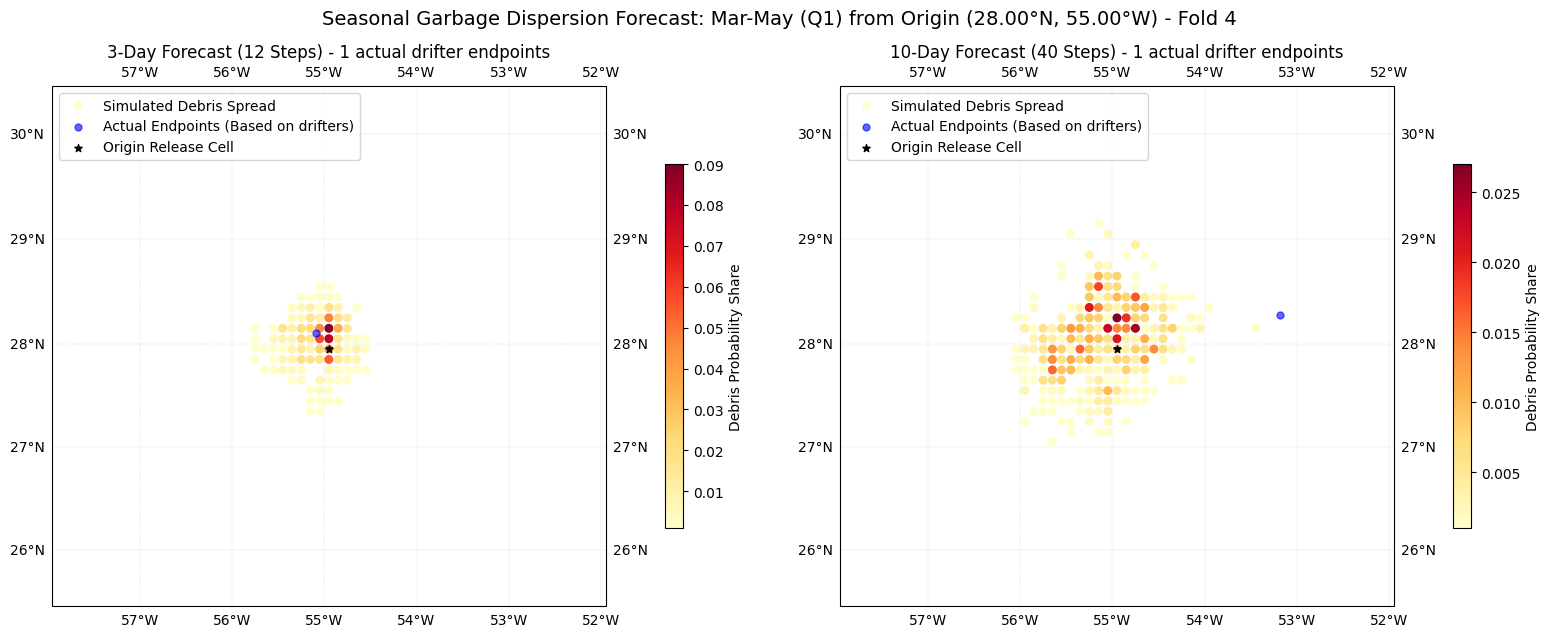

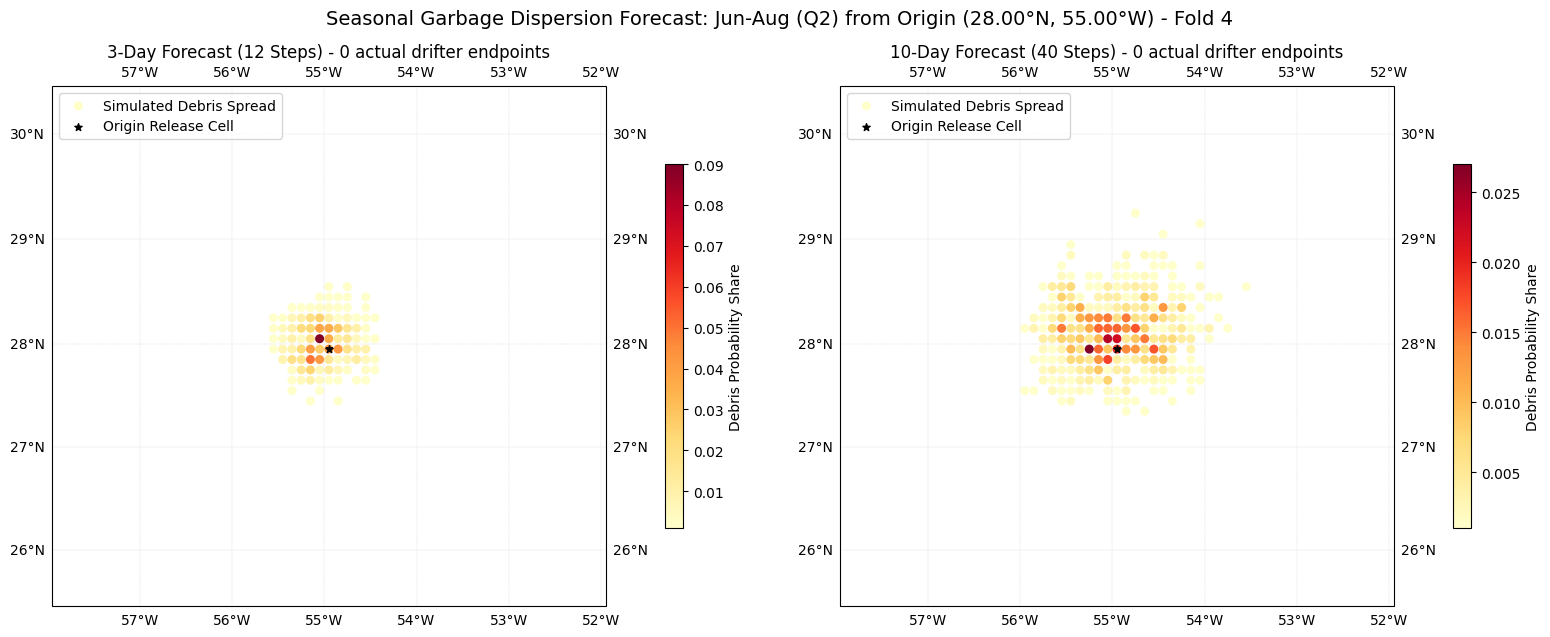

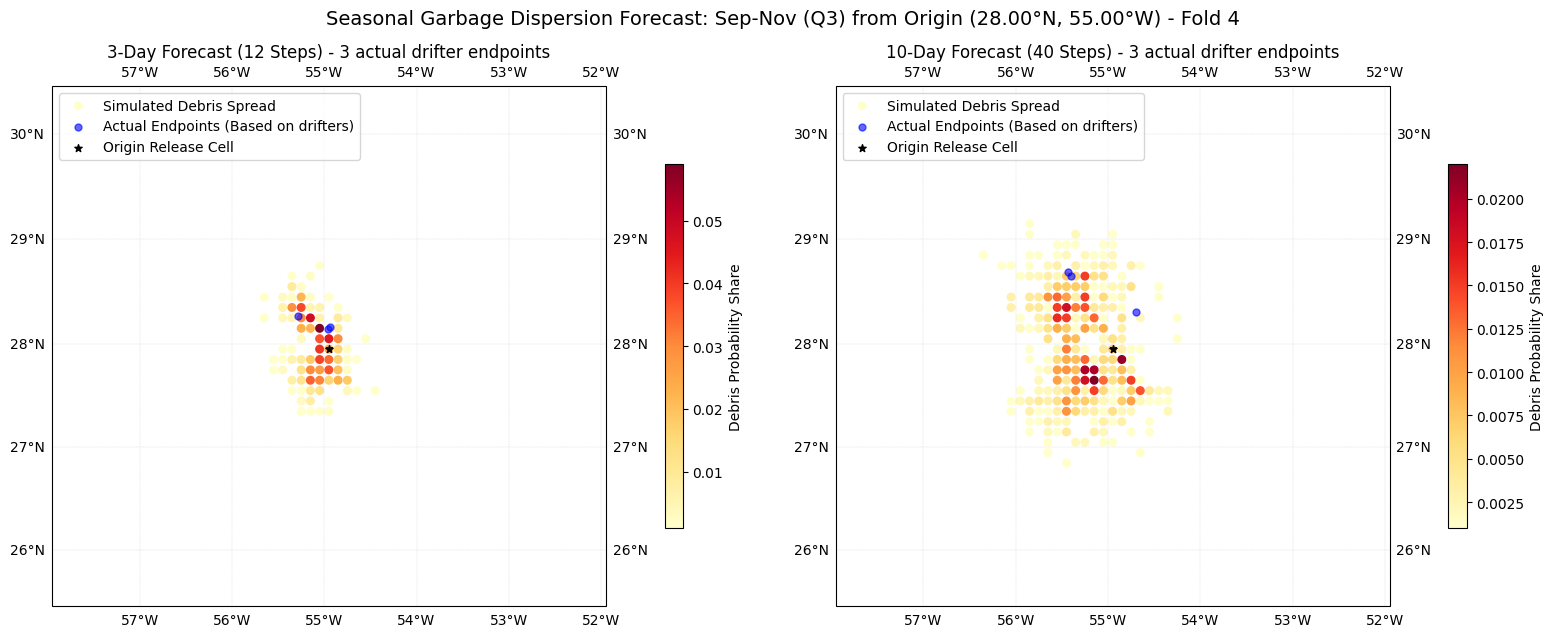

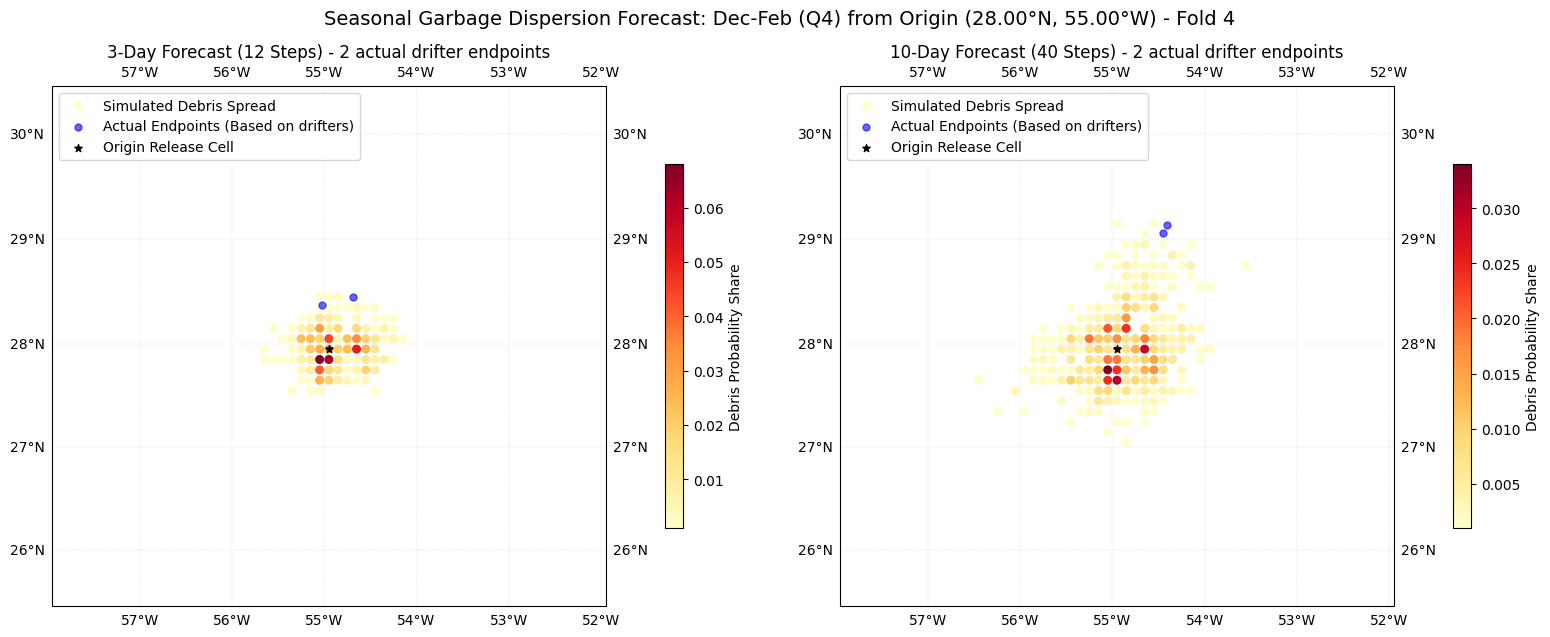

In [ ]:
# ==================================================================
# SEASONAL SINGLE-CELL DISPERSION MAP FORECASTER
# ==================================================================

# Simulates and plots a spatial dispersion forecast from a single origin coordinate for each season's own Markov matrix
def forecast_garbage_patch_fate_seasonal(lat, lon, fold_idx=3, n_sims=1000):
    """
    Simulates and visualises probabilistic debris dispersion from any coordinate,
    using each season's transition matrix, across 3-day and 10-day windows.
    Produces one figure per season (Mar-May, Jun-Aug, Sep-Nov, Dec-Feb).

    Parameters:
        lat: Latitude coordinate of the release origin point.
        lon: Longitude coordinate of the release origin point.
        fold_idx (default=3): Index of the cross-validation fold to pull the seasonal matrices from (3 = Fold 4).
        n_sims (default=1000): Number of Monte Carlo simulation particles to run per horizon.
    """

    # Convert input LAT/LONG into grid and then back to LAT/LONG to get central LAT/LONG of the grid
    cell = int(to_state([lat], [lon])[0])
    latA, lonA = state_to_latlon(cell)

    rec = cv_results[fold_idx]
    fold_num = rec['fold']
    horizons = [(12, "3-Day Forecast (12 Steps)"), (40, "10-Day Forecast (40 Steps)")]

    # One figure per season
    for q, s in rec['seasons'].items():
        sampler = make_sampler(s['P'])          # this season's transition matrix
        rng = np.random.default_rng(42)

        fig, axes = plt.subplots(1, 2, figsize=(16, 6), subplot_kw={'projection': ccrs.Mercator()})

        # Loop through each forecast horizon panel
        for ax, (n_steps, title_label) in zip(axes, horizons):
            ax.set_extent([lonA - 3, lonA + 3, latA - 2.5, latA + 2.5], crs=ccrs.PlateCarree())

            if s['visited'][cell]:
                # Run simulation forward in time for the start cell
                ends = sample_end_states(sampler, [cell], n_steps, n_sims, rng)
                sim_ends = ends[0]

                # Calculate unique destination states and their particle frequency counts
                u, cnts = np.unique(sim_ends, return_counts=True)
                lat_u, lon_u = state_to_latlon(u)

                # Plot simulation spread
                sc = ax.scatter(
                    lon_u, lat_u, c=cnts / cnts.sum(), s=30, cmap='YlOrRd',
                    transform=ccrs.PlateCarree(), label='Simulated Debris Spread'
                )
                plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.08, label='Debris Probability Share')
            else:
                # No training drifter ever left this cell in this season, so there is no forecast
                ax.text(0.5, 0.5, f"Origin cell not visited in {quarter_names[q]} training data",
                        transform=ax.transAxes, ha='center', va='center', fontsize=11)

            # Extract actual test endpoints (held-out drifters, this season only)
            pr = build_pairs_xy(s['df_test'], n_steps=n_steps)
            actual_subset = pr[pr['start'] == cell]
            if len(actual_subset) > 0:
                ax.scatter(
                    actual_subset['lon1'].values, actual_subset['lat1'].values, marker='o', c='blue', s=25,
                    alpha=0.6, transform=ccrs.PlateCarree(), label='Actual Endpoints (Based on drifters)'
                )

            # Plot the starting cell
            ax.scatter(lonA, latA, marker='*', c='black', s=30, transform=ccrs.PlateCarree(), label='Origin Release Cell')

            # Add geographic map features
            ax.add_feature(cfeature.LAND, facecolor='lightgray')
            ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
            ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5, linestyle='--')

            ax.set_title(f"{title_label} - {len(actual_subset)} actual drifter endpoints", fontsize=12)
            ax.legend(loc='upper left')

        plt.suptitle(
            f"Seasonal Garbage Dispersion Forecast: {quarter_names[q]} (Q{q}) from Origin "
            f"({lat:.2f}°N, {abs(lon):.2f}°W) - Fold {fold_num}",
            fontsize=14,
            y=1.02
        )
        plt.tight_layout()
        plt.show()

# Run seasonal visual dispersion maps using Fold 4 (Index 3 in Python)
forecast_garbage_patch_fate_seasonal(lat=28, lon=-55, fold_idx=3)       # 4 figures: Mar-May, Jun-Aug, Sep-Nov, Dec-Feb